In [1]:
import xarray as xr
# import matplotlib as plt
from matplotlib import pyplot as plt
import pandas as pd
import geopandas as gpd
from math import sqrt
import seaborn as sns
import numpy as np
import cartopy


from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import BayesianRidge
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import mean_squared_error, r2_score 
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings('ignore')

#Choose whether to save plots
save_plots = False

# Change the matplotlib dpi to increase or decrease output size in vscode
plt.rcParams['figure.dpi'] = 150 

# Change some of the default xarray settings
xr.set_options(keep_attrs=True, display_expand_data=False)

def rmse(x,y):
    out = sqrt(mean_squared_error(x,y))
    return out


In [65]:
datapath = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/"
dat = pd.read_csv(datapath+"seasonal-dayofweek-no2-estimates.csv")

def F_pixel_stats(dat):
   y_true = dat.sfc_no2_mean
   y_pred = dat.no2_estimate
   bias = (y_pred - y_true).mean() 
   rmse = sqrt(mean_squared_error(y_true, y_pred))
   r2 = r2_score(y_true, y_pred)
   # covar = np.cov(y_true, y_pred, ddof=0)
   covar = np.nan
   out = pd.Series({'r2': r2, 'bias': bias, 'rmse':rmse,
                    'covar': covar})
   return out

pixel_stats = (
    dat.groupby(['latitude','longitude','season','split'])
    .apply(F_pixel_stats)
    .melt(ignore_index=False)
    .reset_index()
               )

print(pixel_stats)

      latitude  longitude  season  split variable     value
0        41.65     -87.61    Fall   test       r2 -0.266116
1        41.65     -87.61    Fall  train       r2 -0.197615
2        41.65     -87.61  Spring   test       r2 -0.264874
3        41.65     -87.61  Spring  train       r2 -0.103466
4        41.65     -87.61  Winter   test       r2  0.002771
...        ...        ...     ...    ...      ...       ...
4051     42.01     -87.67    Fall  train    covar       NaN
4052     42.01     -87.67  Spring   test    covar       NaN
4053     42.01     -87.67  Spring  train    covar       NaN
4054     42.01     -87.67  Winter   test    covar       NaN
4055     42.01     -87.67  Winter  train    covar       NaN

[4056 rows x 6 columns]


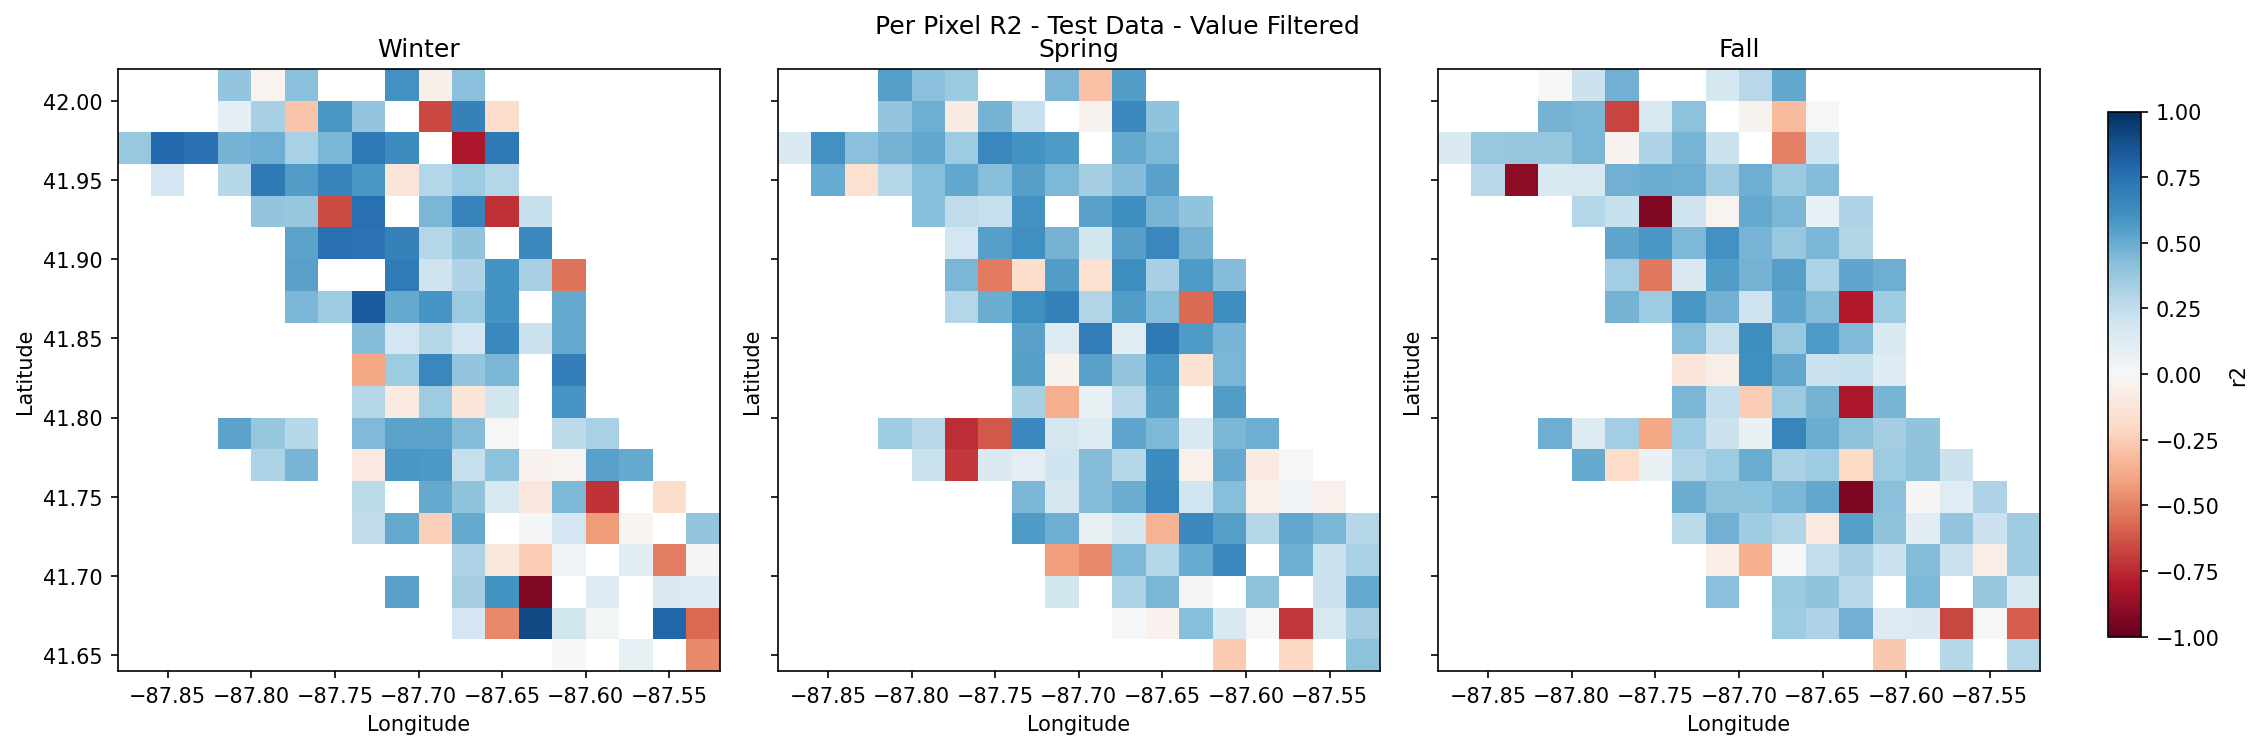

In [41]:
season_order = ['Winter', 'Spring', 'Summer', 'Fall']
seasonal_maps = []

for season in season_order:
    season_subset = pixel_stats.loc[
        (pixel_stats['season'] == season) & (pixel_stats['variable'] == 'r2') & (pixel_stats['split']=='test'),
        ['latitude', 'longitude', 'value']
    ]
    season_subset = season_subset.loc[season_subset['value'] >= -1]
    if season_subset.empty:
        continue

    season_rast = season_subset.set_index(['latitude', 'longitude']).to_xarray()
    seasonal_maps.append((season, season_rast['value']))

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5), sharex=True, sharey=True)
axes = axes.flatten()
mappable = None

for ax, (season, mean_map) in zip(axes, seasonal_maps):
    mappable = mean_map.plot(
        x='longitude',
        y='latitude',
        cmap='RdBu',
        ax=ax,
        add_colorbar=False,
        vmin=-1,
        vmax=1
    )
    ax.set_box_aspect(1)
    ax.set_title(season)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

for ax in axes[len(seasonal_maps):]:
    ax.set_visible(False)

# Reserve space at right for a single shared colorbar
plt.tight_layout(rect=[0, 0, 0.92, 0.97])

if mappable is not None:
    cax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
    fig.colorbar(mappable, cax=cax, label='r2')

fig.suptitle('Per Pixel R2 - Test Data - Value Filtered')
plt.savefig('seasonal-r2-spatial-maps-testdata-filtered.png')
plt.show()

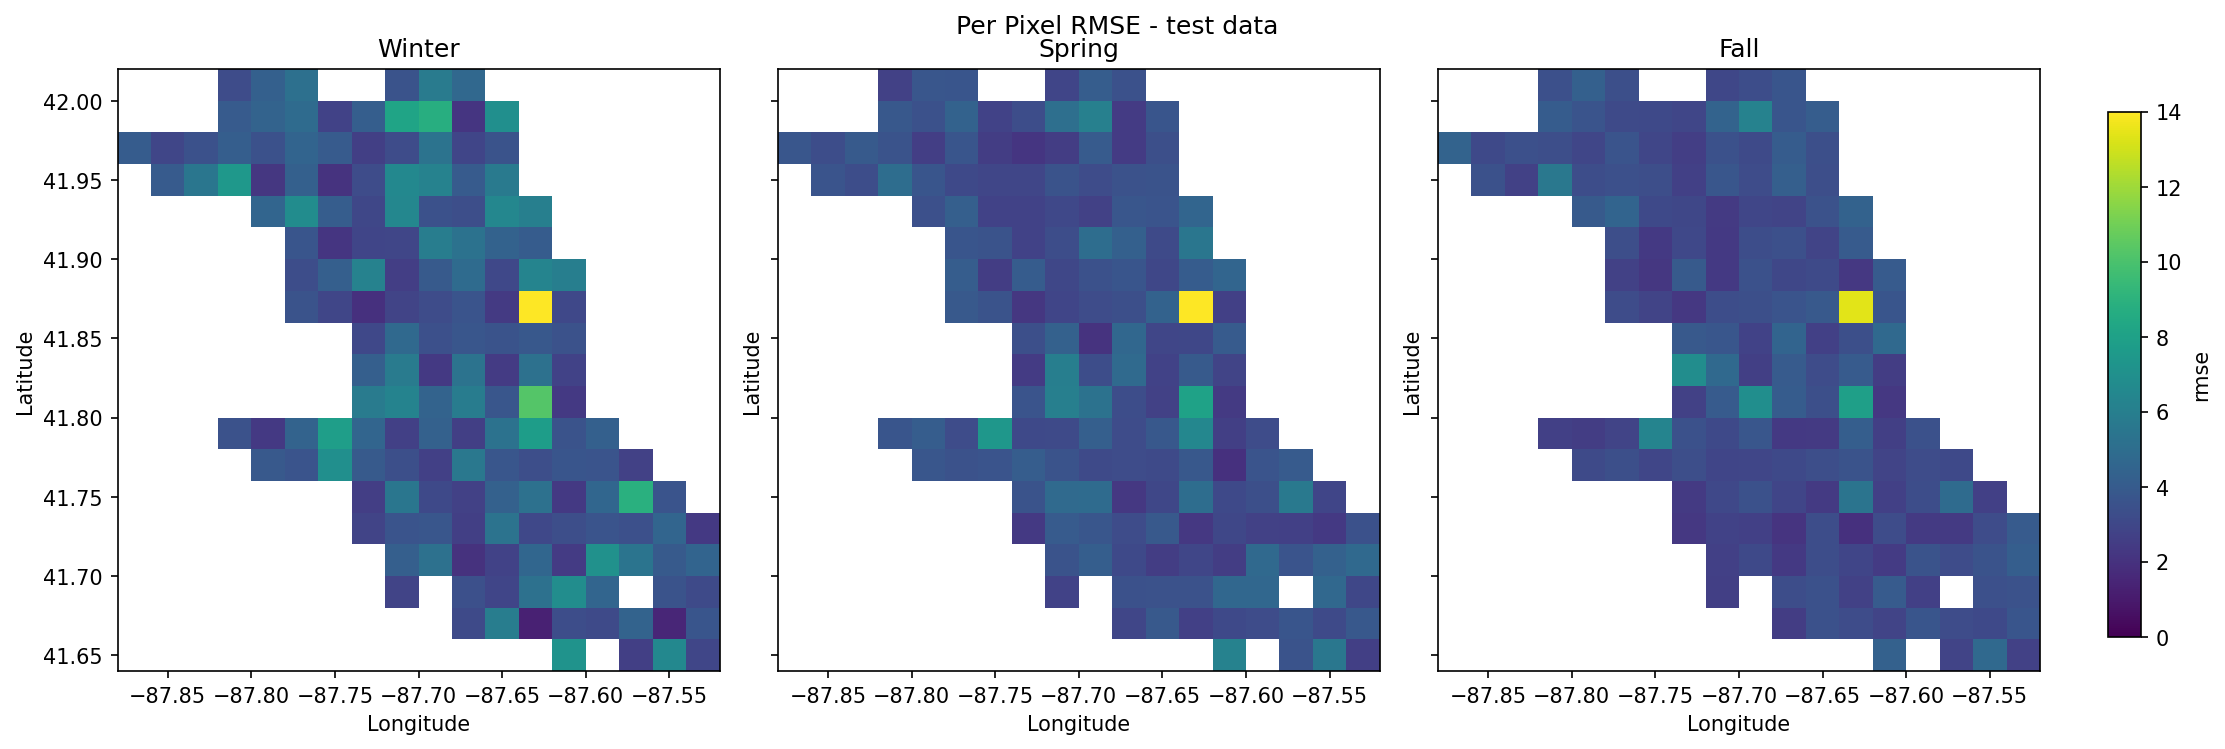

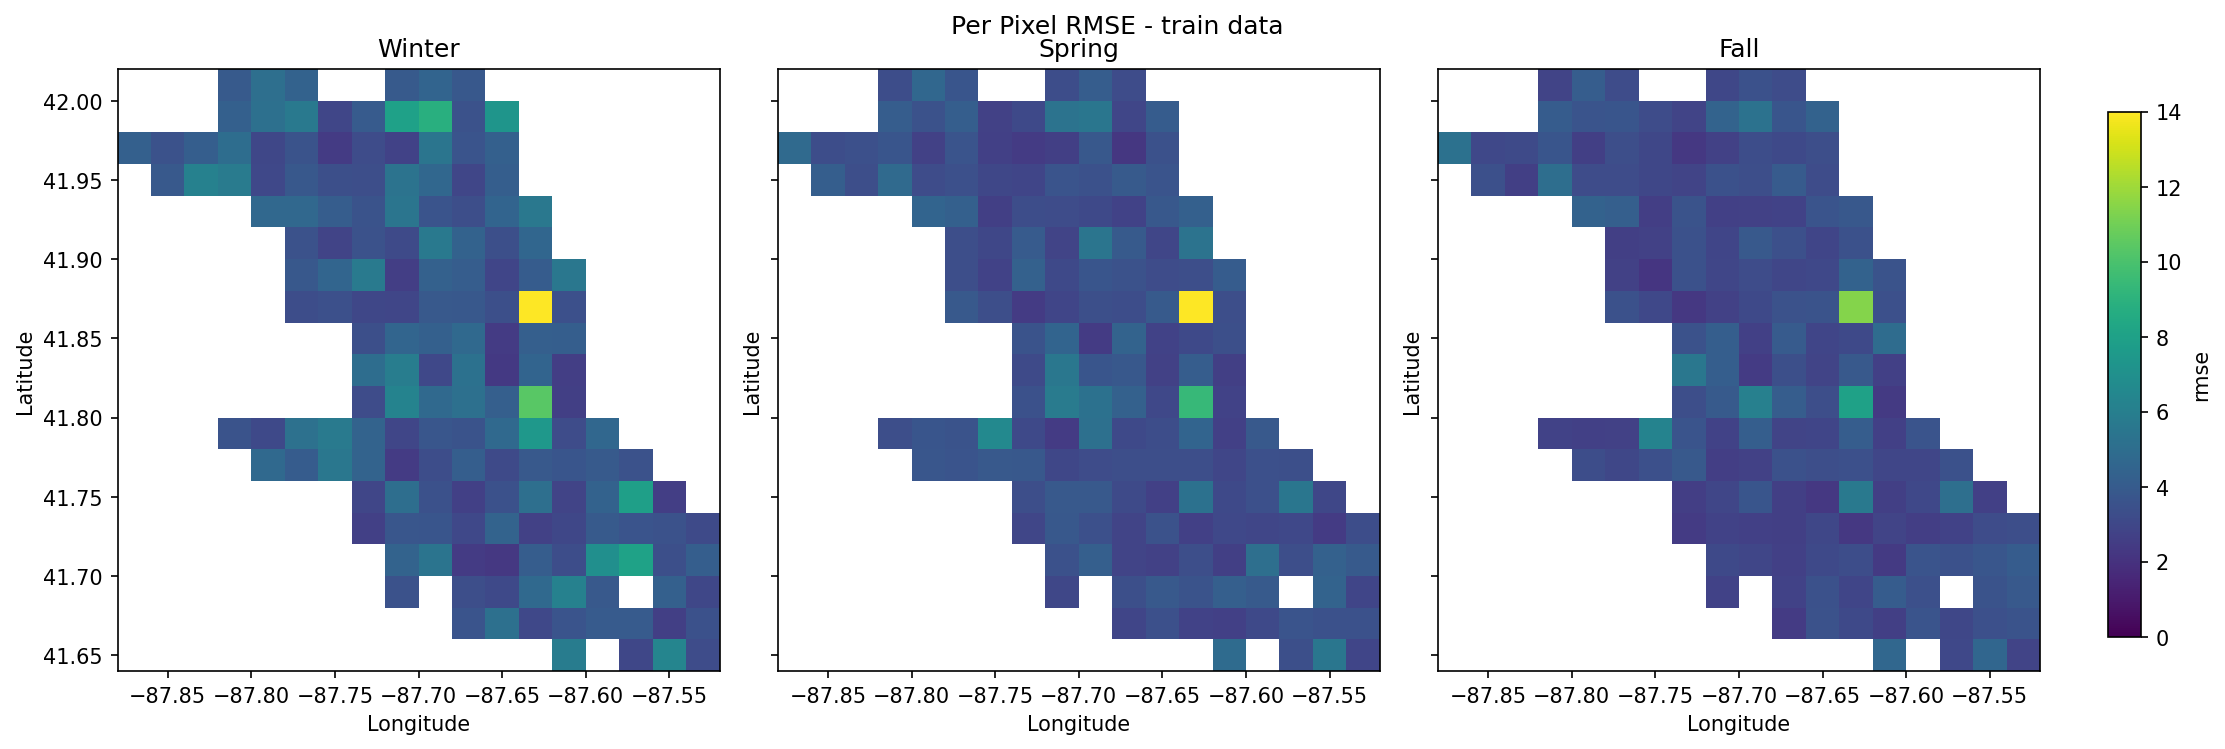

In [59]:
season_order = ['Winter', 'Spring', 'Summer', 'Fall']
splits = ['test','train']

for split in splits:
    seasonal_maps = []
    for season in season_order:
        season_subset = pixel_stats.loc[
            (pixel_stats['season'] == season) & (pixel_stats['variable'] == 'rmse') & (pixel_stats['split']==split),
            ['latitude', 'longitude', 'value']
        ]
        if season_subset.empty:
            continue

        season_rast = season_subset.set_index(['latitude', 'longitude']).to_xarray()
        seasonal_maps.append((season, season_rast['value']))

    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5), sharex=True, sharey=True)
    axes = axes.flatten()
    mappable = None

    for ax, (season, mean_map) in zip(axes, seasonal_maps):
        mappable = mean_map.plot(
            x='longitude',
            y='latitude',
            cmap='viridis',
            ax=ax,
            add_colorbar=False,
            vmin=0,
            vmax=14
        )
        ax.set_box_aspect(1)
        ax.set_title(season)
        ax.set_xlabel('Longitude')
        ax.set_ylabel('Latitude')

    for ax in axes[len(seasonal_maps):]:
        ax.set_visible(False)

    # Reserve space at right for a single shared colorbar
    plt.tight_layout(rect=[0, 0, 0.92, 0.97])

    if mappable is not None:
        cax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
        fig.colorbar(mappable, cax=cax, label='rmse')

    fig.suptitle('Per Pixel RMSE - '+split+' data')
    plt.savefig('seasonal-rmse-spatial-maps-'+split+'-data.png')
    plt.show()

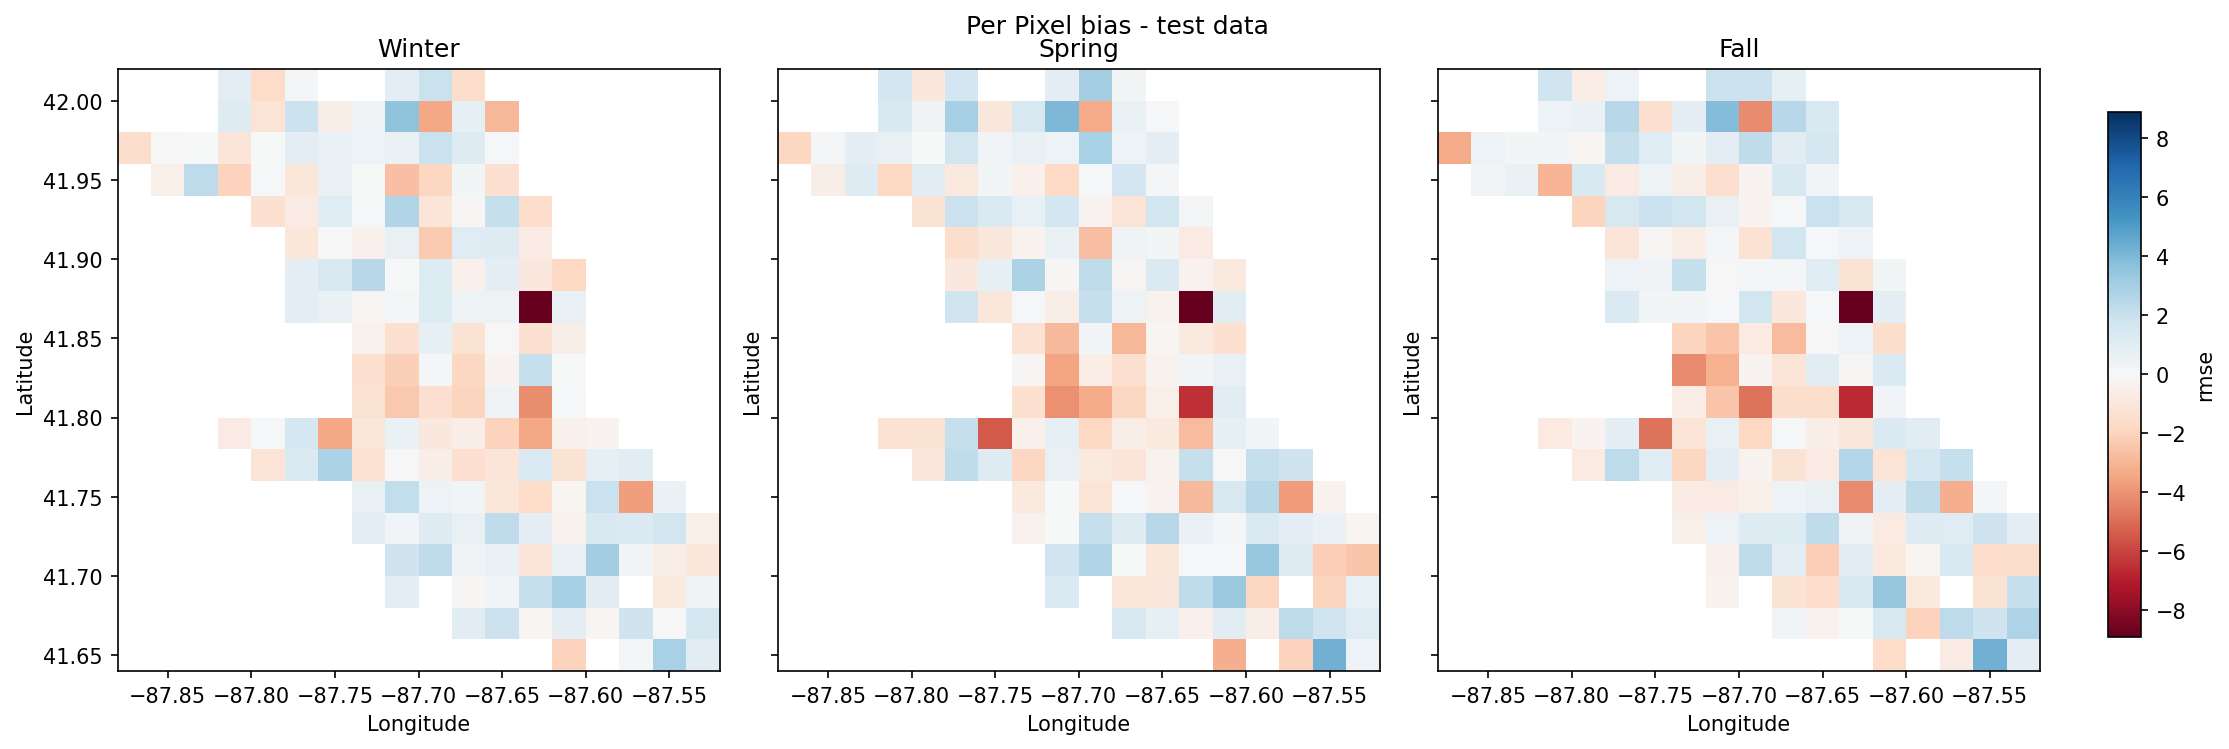

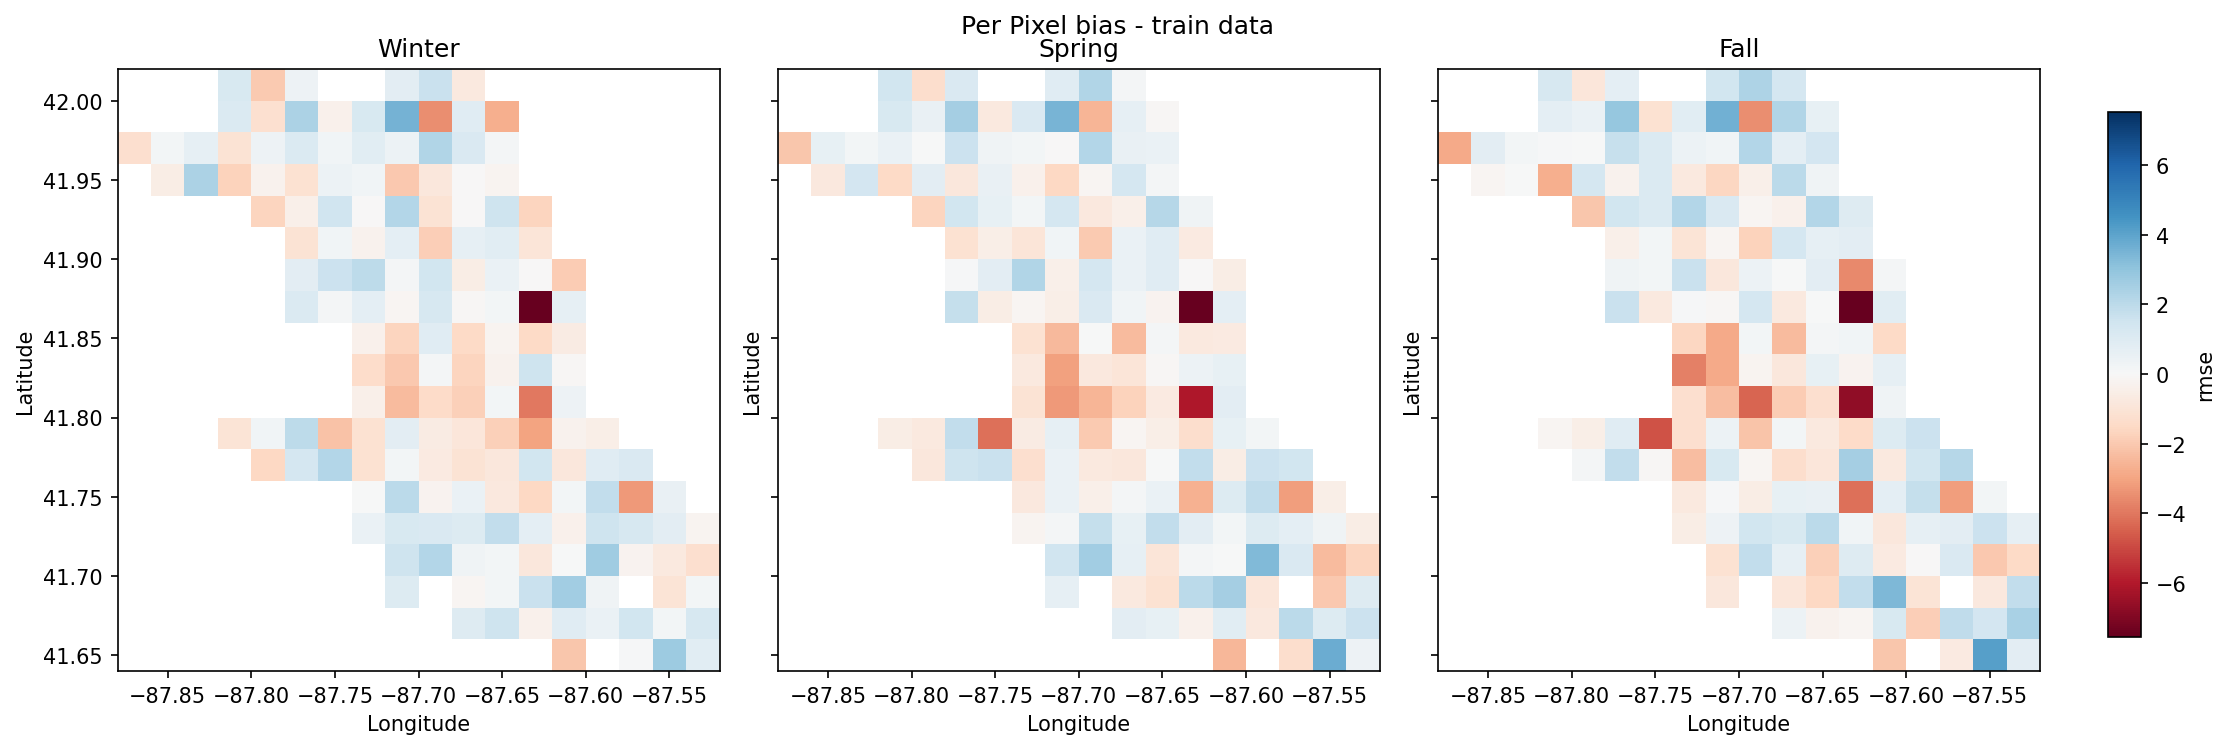

In [ ]:

season_order = ['Winter', 'Spring', 'Summer', 'Fall']
splits = ['test','train']

for split in splits:
    seasonal_maps = []
    for season in season_order:
        season_subset = pixel_stats.loc[
            (pixel_stats['season'] == season) & (pixel_stats['variable'] == 'bias') & (pixel_stats['split']==split),
            ['latitude', 'longitude', 'value']
        ]
        if season_subset.empty:
            continue

        season_rast = season_subset.set_index(['latitude', 'longitude']).to_xarray()
        seasonal_maps.append((season, season_rast['value']))

    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5), sharex=True, sharey=True)
    axes = axes.flatten()
    mappable = None

    for ax, (season, mean_map) in zip(axes, seasonal_maps):
        mappable = mean_map.plot(
            x='longitude',
            y='latitude',
            cmap='RdBu',
            ax=ax,
            add_colorbar=False,
            # vmin=-20,
            # vmax=10
        )
        ax.set_box_aspect(1)
        ax.set_title(season)
        ax.set_xlabel('Longitude')
        ax.set_ylabel('Latitude')

    for ax in axes[len(seasonal_maps):]:
        ax.set_visible(False)

    # Reserve space at right for a single shared colorbar
    plt.tight_layout(rect=[0, 0, 0.92, 0.97])

    if mappable is not None:
        cax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
        fig.colorbar(mappable, cax=cax, label='rmse')

    fig.suptitle('Per Pixel Bias - '+split+' data')
    plt.savefig('seasonal-bias-spatial-maps-'+split+'-data.png')
    plt.show()

TypeError: Plotting requires coordinates to be numeric, boolean, or dates of type numpy.datetime64, datetime.datetime, cftime.datetime or pandas.Interval. Received data of type object instead.

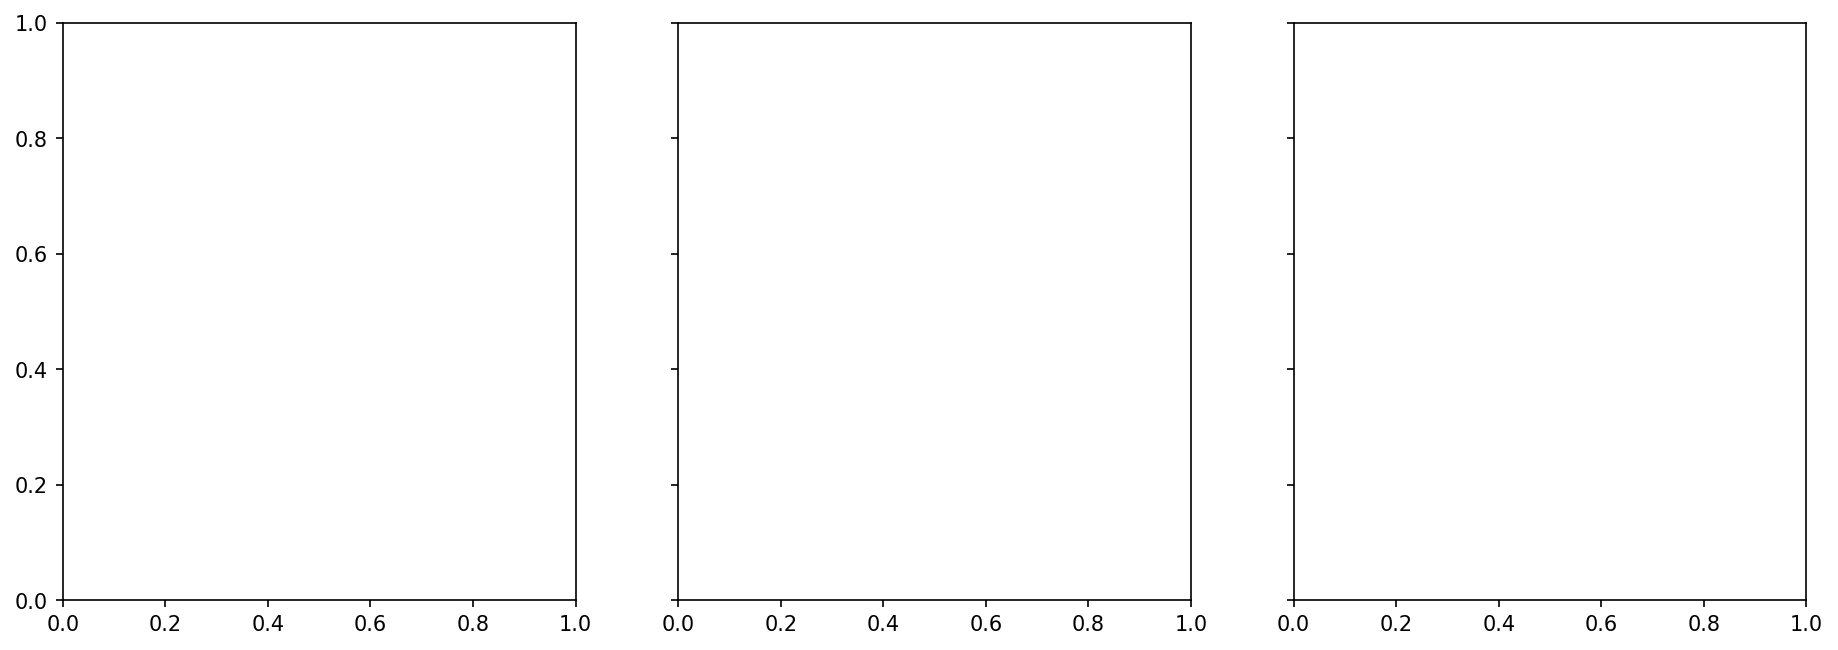

In [62]:

season_order = ['Winter', 'Spring', 'Summer', 'Fall']
splits = ['test','train']

for split in splits:
    seasonal_maps = []
    for season in season_order:
        season_subset = pixel_stats.loc[
            (pixel_stats['season'] == season) & (pixel_stats['variable'] == 'bias') & (pixel_stats['split']==split),
            ['latitude', 'longitude', 'value']
        ]
        if season_subset.empty:
            continue

        season_rast = season_subset.set_index(['latitude', 'longitude']).to_xarray()
        seasonal_maps.append((season, season_rast['value']))

    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5), sharex=True, sharey=True)
    axes = axes.flatten()
    mappable = None

    for ax, (season, mean_map) in zip(axes, seasonal_maps):
        mappable = mean_map.plot(
            x='longitude',
            y='latitude',
            cmap='RdBu',
            ax=ax,
            add_colorbar=False,
            # vmin=-20,
            # vmax=10
        )
        ax.set_box_aspect(1)
        ax.set_title(season)
        ax.set_xlabel('Longitude')
        ax.set_ylabel('Latitude')

    for ax in axes[len(seasonal_maps):]:
        ax.set_visible(False)

    # Reserve space at right for a single shared colorbar
    plt.tight_layout(rect=[0, 0, 0.92, 0.97])

    if mappable is not None:
        cax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
        fig.colorbar(mappable, cax=cax, label='rmse')

    fig.suptitle('Per Pixel Covariance - '+split+' data')
    plt.savefig('seasonal-cov-spatial-maps-'+split+'-data.png')
    plt.show()